# Paper 2

## Notebook 05

# Camera Sensor Confidence Estimation

### Objective

This notebook converts camera quality metrics into a normalized confidence score.

The confidence score is computed from multiple image quality metrics including:

- Brightness
- Contrast
- Blur
- Entropy
- Edge Density
- Noise

The resulting confidence score will later be used for adaptive sensor fusion.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

plt.rcParams["figure.figsize"]=(10,6)
plt.rcParams["figure.dpi"]=150

PROJECT_ROOT = Path.cwd().parent

In [2]:
# ============================================================
# Cell 2
# Load Camera Quality Metrics
# ============================================================

DRIVE = "2011_09_26_drive_0001_sync"

quality_df = pd.read_csv(

    PROJECT_ROOT /

    "results" /

    f"camera_quality_metrics_{DRIVE}.csv"

)

display(quality_df.head())

print("=" * 70)

print("Frames Loaded :", len(quality_df))

print("Drive :", DRIVE)

print("=" * 70)

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame
0,88.167345,74.199336,733.457425,7.136627,251,0.108820,6.017031,0
1,86.974503,73.532517,725.276943,7.123037,250,0.109209,5.987283,1
2,85.261069,73.303896,714.558351,7.107850,250,0.110493,5.946865,2
3,85.619216,73.594935,713.989998,7.124490,252,0.112940,5.947129,3
4,87.901694,74.142102,740.824347,7.169953,252,0.116084,6.061246,4


Frames Loaded : 108
Drive : 2011_09_26_drive_0001_sync


In [3]:
normalized = quality_df.copy()

columns = [

    "Brightness",

    "Contrast",

    "Blur",

    "Entropy",

    "Edge Density"

]

for column in columns:

    normalized[column] = (

        normalized[column]-normalized[column].min()

    )/(

        normalized[column].max()-normalized[column].min()

    )

# Noise is inverse

normalized["Noise"] = 1 - (

    (quality_df["Noise"]-

     quality_df["Noise"].min())

    /

    (quality_df["Noise"].max()-

     quality_df["Noise"].min())

)

display(normalized.head())

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame
0,0.362415,0.824470,0.122920,0.256092,251,0.176659,0.870587,0
1,0.282173,0.744032,0.107438,0.211880,250,0.181919,0.884934,1
2,0.166911,0.716453,0.087152,0.162473,250,0.199297,0.904427,2
3,0.191004,0.751561,0.086077,0.216606,252,0.232426,0.904300,3
4,0.344544,0.817566,0.136863,0.364507,252,0.274970,0.849263,4


In [4]:
weights = {

    "Brightness":0.15,

    "Contrast":0.15,

    "Blur":0.25,

    "Entropy":0.20,

    "Edge Density":0.15,

    "Noise":0.10

}

normalized["Camera Confidence"] = (

      weights["Brightness"] * normalized["Brightness"]

    + weights["Contrast"] * normalized["Contrast"]

    + weights["Blur"] * normalized["Blur"]

    + weights["Entropy"] * normalized["Entropy"]

    + weights["Edge Density"] * normalized["Edge Density"]

    + weights["Noise"] * normalized["Noise"]

)

display(normalized.head())

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence
0,0.362415,0.824470,0.122920,0.256092,251,0.176659,0.870587,0,0.373539
1,0.282173,0.744032,0.107438,0.211880,250,0.181919,0.884934,1,0.338947
2,0.166911,0.716453,0.087152,0.162473,250,0.199297,0.904427,2,0.307125
3,0.191004,0.751561,0.086077,0.216606,252,0.232426,0.904300,3,0.331519
4,0.344544,0.817566,0.136863,0.364507,252,0.274970,0.849263,4,0.407605


In [5]:
def classify(score):

    if score>=0.90:

        return "Excellent"

    elif score>=0.75:

        return "High"

    elif score>=0.60:

        return "Moderate"

    elif score>=0.40:

        return "Low"

    else:

        return "Poor"


normalized["Confidence Level"] = (

    normalized["Camera Confidence"]

    .apply(classify)

)

display(normalized.head())

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence,Confidence Level
0,0.362415,0.824470,0.122920,0.256092,251,0.176659,0.870587,0,0.373539,Poor
1,0.282173,0.744032,0.107438,0.211880,250,0.181919,0.884934,1,0.338947,Poor
2,0.166911,0.716453,0.087152,0.162473,250,0.199297,0.904427,2,0.307125,Poor
3,0.191004,0.751561,0.086077,0.216606,252,0.232426,0.904300,3,0.331519,Poor
4,0.344544,0.817566,0.136863,0.364507,252,0.274970,0.849263,4,0.407605,Low


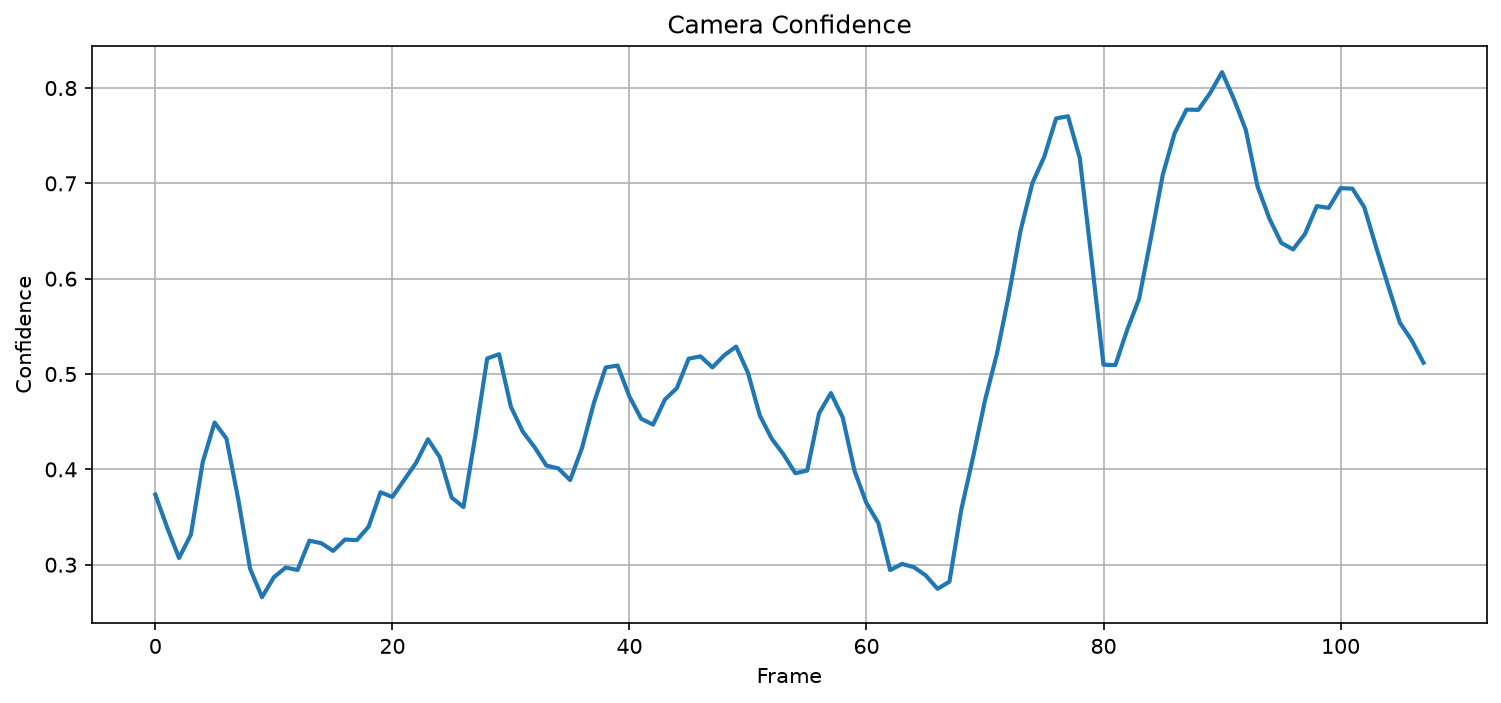

In [6]:
plt.figure(figsize=(12,5))

plt.plot(

    normalized["Frame"],

    normalized["Camera Confidence"],

    linewidth=2

)

plt.title("Camera Confidence")

plt.xlabel("Frame")

plt.ylabel("Confidence")

plt.grid(True)

plt.show()

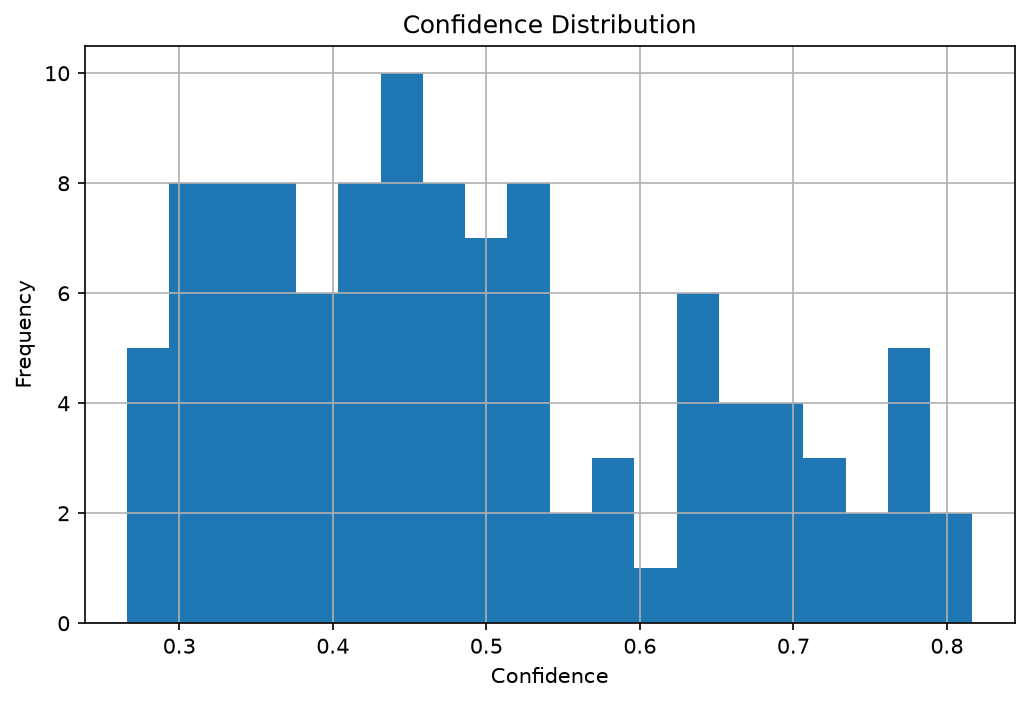

In [7]:
plt.figure(figsize=(8,5))

plt.hist(

    normalized["Camera Confidence"],

    bins=20

)

plt.title("Confidence Distribution")

plt.xlabel("Confidence")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

In [8]:
class_counts = (

    normalized["Confidence Level"]

    .value_counts()

)

display(class_counts)

Confidence Level
Low         47
Poor        34
Moderate    18
High         9
Name: count, dtype: int64

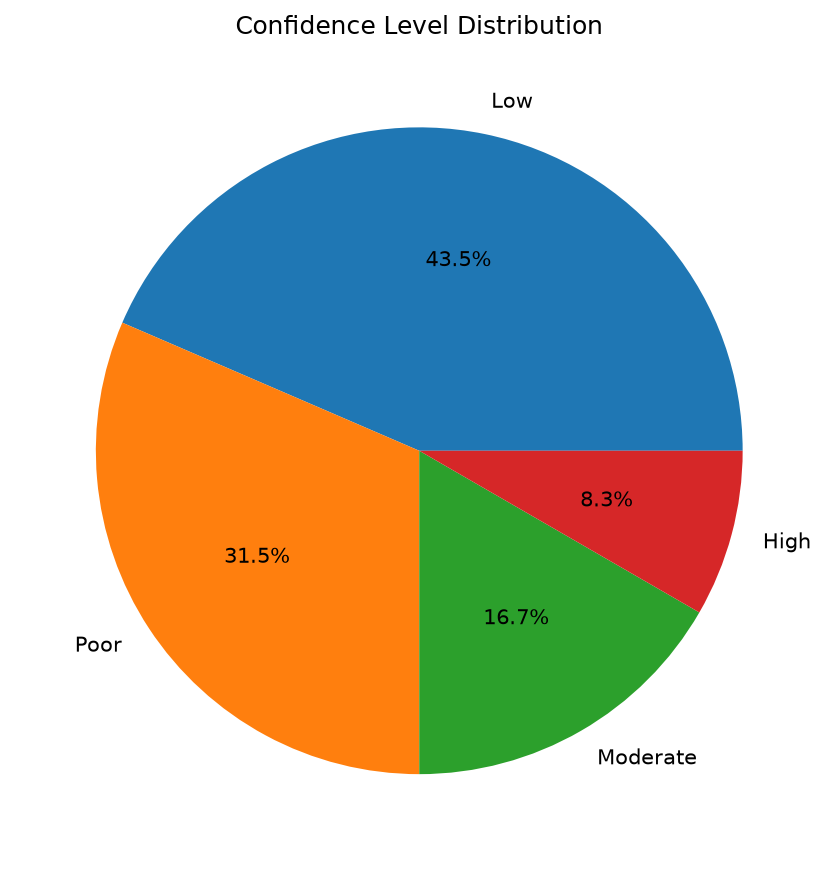

In [9]:
plt.figure(figsize=(7,7))

plt.pie(

    class_counts,

    labels=class_counts.index,

    autopct="%1.1f%%"

)

plt.title("Confidence Level Distribution")

plt.show()

In [10]:
top_frames = (

    normalized

    .sort_values(

        "Camera Confidence",

        ascending=False

    )

    .head(len(normalized))

)

display(top_frames)

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence,Confidence Level
90,1.000000,0.468846,1.000000,0.981506,250,1.000000,0.000000,90,0.816628,High
89,0.923910,0.511905,0.977224,0.945629,250,0.961873,0.017274,89,0.794812,High
91,0.907580,0.459296,0.980294,0.947666,251,0.980965,0.016022,91,0.788385,High
87,0.910089,0.603386,0.932548,0.898353,248,0.880067,0.055197,87,0.777359,High
88,0.887070,0.546951,0.948698,0.920330,251,0.911598,0.040003,88,0.777084,High
...,...,...,...,...,...,...,...,...,...,...
65,0.068263,0.055070,0.264932,0.460673,252,0.293511,0.678979,65,0.288792,Poor
10,0.240238,0.785119,0.053796,0.069213,250,0.077214,0.942073,10,0.286885,Poor
67,0.041643,0.211024,0.342400,0.210550,254,0.379414,0.596907,67,0.282213,Poor
66,0.000000,0.114342,0.295736,0.333072,250,0.349220,0.646370,66,0.274720,Poor


In [11]:
worst_frames = (

    normalized

    .sort_values(

        "Camera Confidence"

    )

    .head(50)

)

display(worst_frames)

,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence,Confidence Level
9,0.250123,0.767648,0.000000,0.000000,250,0.088751,1.000000,9,0.265978,Poor
66,0.000000,0.114342,0.295736,0.333072,250,0.349220,0.646370,66,0.274720,Poor
67,0.041643,0.211024,0.342400,0.210550,254,0.379414,0.596907,67,0.282213,Poor
10,0.240238,0.785119,0.053796,0.069213,250,0.077214,0.942073,10,0.286885,Poor
65,0.068263,0.055070,0.264932,0.460673,252,0.293511,0.678979,65,0.288792,Poor
62,0.147767,0.000000,0.205933,0.606840,251,0.161402,0.751031,62,0.294330,Poor
12,0.219080,0.821411,0.058366,0.129979,251,0.025631,0.939800,12,0.294486,Poor
8,0.320175,0.758991,0.020493,0.067960,249,0.117346,0.975434,8,0.295736,Poor
11,0.230506,0.780301,0.066989,0.140603,250,0.049316,0.931377,11,0.297024,Poor
64,0.126863,0.028364,0.236278,0.526019,251,0.255354,0.715449,64,0.297405,Poor


In [12]:
# ============================================================
# Cell 12
# Confidence Statistics
# ============================================================

statistics = normalized[

    ["Camera Confidence"]

].describe()

display(statistics)

,Camera Confidence
count,108.000000
mean,0.490494
std,0.148791
min,0.265978
25%,0.372924
50%,0.462247
75%,0.599867
max,0.816628


In [13]:
# ============================================================
# Cell 13
# Save Results
# ============================================================

RESULT_DIR = PROJECT_ROOT / "results"

normalized.to_csv(

    RESULT_DIR /

    f"camera_confidence_{DRIVE}.csv",

    index=False

)

statistics.to_csv(

    RESULT_DIR /

    f"camera_confidence_statistics_{DRIVE}.csv"

)

print("=" * 70)

print("Files Saved Successfully")

print("=" * 70)

print(f"camera_confidence_{DRIVE}.csv")

print(f"camera_confidence_statistics_{DRIVE}.csv")

print("=" * 70)

Files Saved Successfully
camera_confidence_2011_09_26_drive_0001_sync.csv
camera_confidence_statistics_2011_09_26_drive_0001_sync.csv


In [14]:
# ============================================================
# Cell 14
# Final Summary
# ============================================================

print("=" * 80)

print("NOTEBOOK 05 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print("Frames Processed :", len(normalized))

print()

print(

    f"Average Confidence : "

    f"{normalized['Camera Confidence'].mean():.3f}"

)

print(

    f"Highest Confidence : "

    f"{normalized['Camera Confidence'].max():.3f}"

)

print(

    f"Lowest Confidence : "

    f"{normalized['Camera Confidence'].min():.3f}"

)

print()

print("Generated Files")

print("-----------------------------")

print(f"camera_confidence_{DRIVE}.csv")

print(f"camera_confidence_statistics_{DRIVE}.csv")

print()

print("READY FOR NOTEBOOK 06")

print("=" * 80)

NOTEBOOK 05 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync
Frames Processed : 108

Average Confidence : 0.490
Highest Confidence : 0.817
Lowest Confidence : 0.266

Generated Files
-----------------------------
camera_confidence_2011_09_26_drive_0001_sync.csv
camera_confidence_statistics_2011_09_26_drive_0001_sync.csv

READY FOR NOTEBOOK 06
